# Which frequencies are in one guitar note?

Our goal is audio → pitches and attack times → plausible guitar tabs.
This first step measures a spectrum: how strongly different frequencies appear
in one short segment. It does **not** yet decide the fundamental pitch or tab.
Run from the project folder, one cell at a time in the matching notebook.

## 1. Select a ringing portion of low E
Sample rate describes how often we measure amplitude, not the note's pitch.
At 44,100 samples/second, samples are 1/44,100 seconds apart.
A frequency of 82 Hz means roughly 82 vibration cycles per second.

We manually choose 3.0–3.5 seconds because our earlier inspection put this
take's attack near 2.45 seconds. This is an editable inspection window, **not**
an assumed silence duration or an automatic onset rule. It avoids needing an
exact note ending. Keep this same duration when comparing steady segments.


In [1]:
from pathlib import Path
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt

file_path = Path("data/raw/Low_E_note_dry_take02.wav")
start_seconds = 3.0
stop_seconds = 3.5

samples, sample_rate = sf.read(file_path)
signal = samples[:, 0] if samples.ndim == 2 else samples
start_sample = round(start_seconds * sample_rate)
stop_sample = round(stop_seconds * sample_rate)
if not 0 <= start_sample < stop_sample <= len(signal):
    raise ValueError("Choose a segment entirely inside the recording.")
segment = signal[start_sample:stop_sample]
if len(segment) < 4 or not np.all(np.isfinite(segment)):
    raise ValueError("Choose at least four finite samples.")

sample_count = len(segment)
duration = sample_count / sample_rate
print(file_path.name)
print(f"Sample rate: {sample_rate:,} samples/second")
print(f"Original indices: [{start_sample}:{stop_sample}] (stop excluded)")
print(f"Segment: {sample_count:,} samples / {sample_rate:,} = {duration:.3f} seconds")


Low_E_note_dry_take02.wav
Sample rate: 44,100 samples/second
Original indices: [132300:154350] (stop excluded)
Segment: 22,050 samples / 44,100 = 0.500 seconds


## 2. See where those samples came from
The shaded interval is on the original file timeline. The close-up shows
repeating vibration; it is the first 0.05 seconds of our selected segment.
That plot duration only controls the view, not the FFT calculation below.


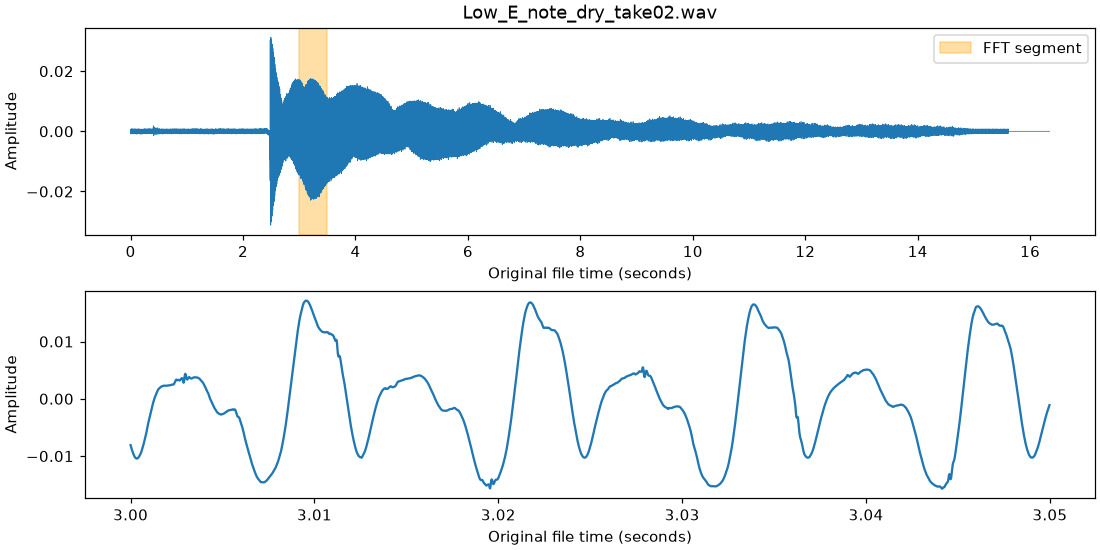

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5), constrained_layout=True)
axes[0].plot(np.arange(len(signal)) / sample_rate, signal, linewidth=0.5)
axes[0].axvspan(start_sample / sample_rate, stop_sample / sample_rate,
                color="orange", alpha=0.35, label="FFT segment")
axes[0].set(title=file_path.name, xlabel="Original file time (seconds)", ylabel="Amplitude")
axes[0].legend()
zoom_count = min(sample_count, round(0.05 * sample_rate))
axes[1].plot((start_sample + np.arange(zoom_count)) / sample_rate, segment[:zoom_count])
axes[1].set(xlabel="Original file time (seconds)", ylabel="Amplitude")
plt.show()


## 3. Turn the segment into a frequency spectrum
Imagine comparing the waveform with repeating waves at different frequencies.
The FFT computes those comparisons efficiently.

- Subtract the mean to remove a constant offset (DC), which is not vibration.
- Multiply by a **Hann window**: gently taper the segment's edges toward zero.
  This reduces spectral spreading caused by abruptly cutting the waveform.
  It also broadens peaks; it does not magically increase frequency resolution.
- `rfft` returns complex coefficients; `abs` gives their magnitudes.
- `rfftfreq` labels the coefficients in Hz using the sample spacing `1 / sample_rate`.

Bin spacing = sample_rate / sample_count = 1 / duration.
For 22,050 samples at 44,100 Hz, the frequency grid is 0, 2, 4, ... 22,050 Hz.
**2 Hz is the grid spacing, not a guaranteed pitch accuracy.** A half-second
window is useful for this sustained-note lesson but can mix several fast notes.
Magnitudes below are uncalibrated FFT values, not RMS, loudness, or probabilities.


In [3]:
centered = segment - np.mean(segment)
window = np.hanning(sample_count)
windowed = centered * window
spectrum = np.fft.rfft(windowed)
magnitudes = np.abs(spectrum)
frequencies = np.fft.rfftfreq(sample_count, d=1 / sample_rate)
bin_spacing = sample_rate / sample_count

# Skip the zero-frequency bin. This finds a dominant component, not necessarily pitch.
if not np.any(magnitudes[1:] > 0):
    raise ValueError("This segment has no varying signal to analyze.")
peak_index = 1 + np.argmax(magnitudes[1:])
dominant_frequency = frequencies[peak_index]
print(f"FFT grid spacing: {bin_spacing:.2f} Hz")
print(f"Strongest nonzero frequency bin: {dominant_frequency:.2f} Hz")
print("A strongest bin alone does not establish the fundamental or even that a note is present.")


FFT grid spacing: 2.00 Hz
Strongest nonzero frequency bin: 164.00 Hz
A strongest bin alone does not establish the fundamental or even that a note is present.


## 4. Read the spectrum before calling it a pitch
For a pitched string, the fundamental is the base repetition frequency;
harmonics appear approximately at 2×, 3×, 4× that frequency. One guitar note
can therefore make many peaks. A stronger second harmonic can make a simple
largest-peak detector report an octave too high.

This low-E take's 3.0–3.5 s example has its largest bin at **164 Hz**, with a
lower peak near **82 Hz**. That pattern is consistent with low E and a stronger
second harmonic; it is not two automatically identified notes. The code never
uses the filename or an expected E frequency to choose its largest peak.

The graph zooms to 0–1,000 Hz for readability; the calculation searched all
nonzero bins. The y-axis is relative to this segment's maximum, so do not use
it to compare recording volumes. Original audio is never changed.


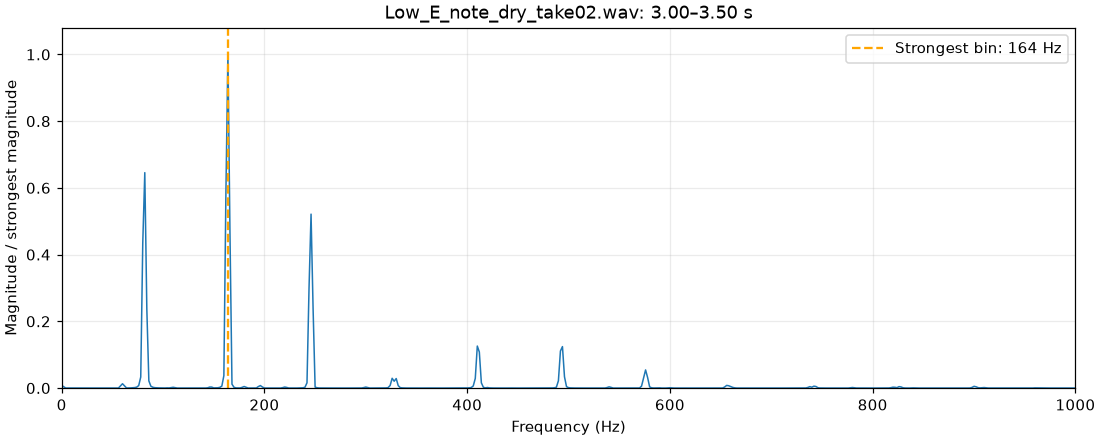

In [4]:
relative_magnitude = magnitudes / magnitudes[peak_index]
fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
ax.plot(frequencies, relative_magnitude, linewidth=1)
ax.set(xlim=(0, 1000), ylim=(0, 1.08), xlabel="Frequency (Hz)",
       ylabel="Magnitude / strongest magnitude",
       title=f"{file_path.name}: {start_sample / sample_rate:.2f}–{stop_sample / sample_rate:.2f} s")
if dominant_frequency <= 1000:
    ax.axvline(dominant_frequency, color="orange", linestyle="--",
               label=f"Strongest bin: {dominant_frequency:.0f} Hz")
    ax.legend()
ax.grid(alpha=0.25)
plt.show()


## Stop here and compare
Change only `file_path` to `data/raw/Low_E_note_dry_take01.wav`, then rerun
all cells. In that take, this segment's strongest bin is about **82 Hz**.
The two takes illustrate why largest peak ≠ reliable fundamental detector.
Try A take01 next; its strongest bin is around **110 Hz** in this interval.
These are inspection examples, not held-out evaluation or tuning targets.

Our next small step is to estimate the fundamental using repeating waveform
structure or harmonic spacing and test it on both E takes, A, and C. After that,
move the analysis window through a known short melody and combine pitch with
new-attack detection. Chords need a later multipitch method.

API references: [NumPy rfft](https://numpy.org/doc/stable/reference/generated/numpy.fft.rfft.html),
[rfftfreq](https://numpy.org/doc/stable/reference/generated/numpy.fft.rfftfreq.html),
[Hann window](https://numpy.org/doc/stable/reference/generated/numpy.hanning.html).
